# Model evaluation and interpretation

We evaluate the models fitted in Notebook 03 on the held-out respondents.

## 1 Import libraries and load the data and models

We load the same test rows used in Notebook 03.

In [2]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
processed = root / "data/processed"
tables = root / "results/tables/modelling"
figures = root / "results/figures/presentation2"
sample = pd.read_csv(processed / "eu_loneliness_analysis_sample.csv")

saved = joblib.load(processed / "presentation2_models.joblib")
test = sample.loc[saved["test"]]
observed = test["ucla_total"]
selected = saved["selected"]

## 2 Generate predictions and calculate test errors

We compared the models on the test set. MAE is the average prediction error in loneliness points, while RMSE gives larger errors more weight.

In [3]:
predictions = pd.DataFrame({name: model.predict(test[saved["full"]])
                            for name, model in saved["models"].items()}, index=test.index)
contact_predictions = pd.DataFrame({
    name: model.predict(test[saved["predictor_sets"][name]])
    for name, model in saved["ridge_models"].items()
}, index=test.index)

def test_metrics(predicted):
    return pd.DataFrame({
        "MAE": predicted.apply(lambda p: mean_absolute_error(observed, p)),
        "RMSE": predicted.apply(lambda p: root_mean_squared_error(observed, p)),
        "R2": predicted.apply(lambda p: r2_score(observed, p)),
        "outside_score_range": ((predicted < 3) | (predicted > 9)).sum(),
    })

for filename, predicted in [("final_test_metrics", predictions),
                            ("predictor_sets_test", contact_predictions)]:
    metrics = test_metrics(predicted)
    metrics.to_csv(tables / (filename + ".csv"))
    display(metrics.round(3))

,MAE,RMSE,R2,outside_score_range
Random forest,1.397,1.699,0.158,0
Median baseline,1.556,1.851,-0.000,0
Mean baseline,1.557,1.851,-0.000,0


,MAE,RMSE,R2,outside_score_range
Face-to-face only,1.543,1.821,0.033,0
Remote only,1.552,1.835,0.017,0
Both contact types,1.539,1.821,0.033,0
Context only,1.458,1.755,0.101,10
Context + face-to-face,1.422,1.726,0.131,9
Context + remote,1.431,1.738,0.118,7
Context + both,1.418,1.725,0.132,8


## 3 Compare results with and without survey weights

The EU27 weight adjusts for differences in sample composition and country population size. We use it to check whether the contact associations and test errors change when respondents contribute different amounts to the results.

,unweighted_rho,unweighted_p,weighted_rho
contact,,,
friends_meet_face,-0.173,0.0,-0.142
friends_meet_tele,-0.139,0.0,-0.102


,unweighted_MAE,weighted_MAE
Random forest,1.397,1.390
Median baseline,1.556,1.567
Mean baseline,1.557,1.567
Face-to-face only,1.543,1.568
Remote only,1.552,1.578
Both contact types,1.539,1.568
Context only,1.458,1.445
Context + face-to-face,1.422,1.418
Context + remote,1.431,1.429
Context + both,1.418,1.418


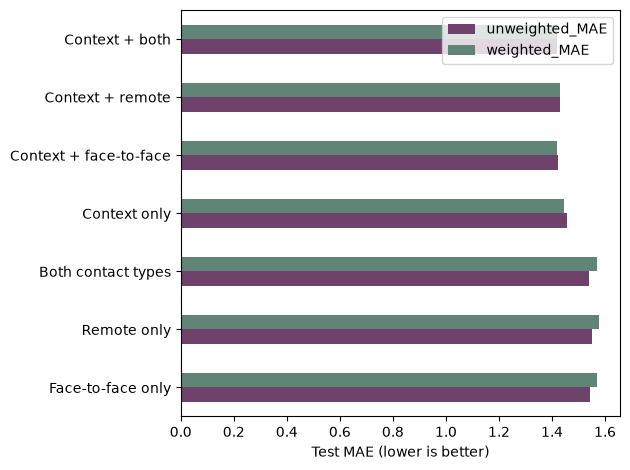

In [4]:
weights = sample["w_eu27"]
if not np.isfinite(weights).all() or not weights.gt(0).all():
    raise ValueError("The analysis sample must have a positive EU27 weight for each respondent.")

def weighted_ranks(values, weights):
    # Tied values share the midpoint of their combined survey weight.
    totals = weights.groupby(values, sort=True).sum()
    return values.map(totals.cumsum() - totals / 2)

def weighted_correlation(x, y, weights):
    x = x - np.average(x, weights=weights)
    y = y - np.average(y, weights=weights)
    return np.average(x * y, weights=weights) / np.sqrt(
        np.average(x ** 2, weights=weights) * np.average(y ** 2, weights=weights)
    )

rho = []
for column in ["friends_meet_face", "friends_meet_tele"]:
    contact, loneliness = sample[column], sample["ucla_total"]
    ordinary = spearmanr(contact, loneliness)
    weighted = weighted_correlation(weighted_ranks(contact, weights),
                                    weighted_ranks(loneliness, weights), weights)
    rho.append({"contact": column, "unweighted_rho": ordinary.statistic,
                "unweighted_p": ordinary.pvalue, "weighted_rho": weighted})
correlations = pd.DataFrame(rho).set_index("contact")
correlations.to_csv(tables / "spearman_weight_comparison.csv")
display(correlations.round(3))

all_predictions = pd.concat([predictions, contact_predictions], axis=1)
errors = all_predictions.sub(observed, axis=0).abs()
weighted_mae = pd.DataFrame({
    "unweighted_MAE": errors.mean(),
    "weighted_MAE": errors.apply(lambda e: np.average(e, weights=weights.loc[e.index])),
})
weighted_mae.to_csv(tables / "test_mae_weight_comparison.csv")
display(weighted_mae.round(3))
ax = weighted_mae.loc[contact_predictions.columns].plot.barh(color=["#6e426a", "#608475"])
ax.set(xlabel="Test MAE (lower is better)", ylabel="")
plt.tight_layout()
plt.savefig(figures / "03_predictor_sets_test.png", dpi=180)
plt.show()

## 4 Compare test errors on the same respondents

We resample the same respondents for both models in each pair. This lets us estimate how uncertain the improvement is while keeping the comparison between predictions for the same people.

In [5]:
rng = np.random.default_rng(42)
pairs = [("Remote only", "Face-to-face only"), ("Context only", "Context + both"),
         ("Context + remote", "Context + both"), ("Context + face-to-face", "Context + both")]
if selected != "Median baseline":
    pairs.append(("Median baseline", selected))
differences = pd.DataFrame({f"{a} → {b}": errors[a] - errors[b] for a, b in pairs})
draws = np.array([differences.to_numpy()[rng.integers(len(test), size=len(test))].mean(axis=0)
                  for _ in range(2000)])
intervals = pd.DataFrame({"MAE improvement": differences.mean(),
                          "95% lower": np.quantile(draws, .025, axis=0),
                          "95% upper": np.quantile(draws, .975, axis=0)})
intervals.to_csv(tables / "paired_test_mae_comparisons.csv")
display(intervals.round(3))

,MAE improvement,95% lower,95% upper
Remote only → Face-to-face only,0.009,0.002,0.017
Context only → Context + both,0.040,0.031,0.050
Context + remote → Context + both,0.013,0.008,0.018
Context + face-to-face → Context + both,0.004,0.001,0.008
Median baseline → Random forest,0.160,0.140,0.178


## 5 Check predictions across the score range

We checked whether the model overpredicted low loneliness scores or underpredicted high scores.

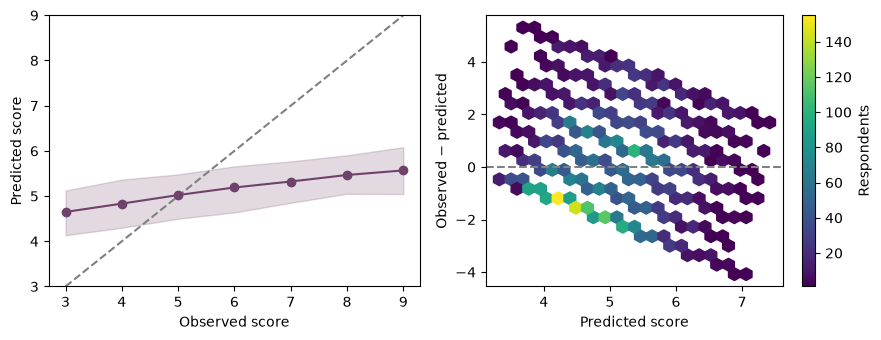

In [6]:
diagnostics = pd.DataFrame({"observed": observed, "predicted": predictions[selected]})
diagnostics["residual"] = diagnostics["observed"] - diagnostics["predicted"]
by_score = diagnostics.groupby("observed")["predicted"].agg(
    n="size", mean="mean", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75)
)
by_score.to_csv(tables / "errors_by_observed_score.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot([3, 9], [3, 9], "--", color="grey")
axes[0].plot(by_score.index, by_score["mean"], "o-", color="#6e426a")
axes[0].fill_between(by_score.index, by_score["q25"], by_score["q75"], alpha=.2, color="#6e426a")
axes[0].set(xlabel="Observed score", ylabel="Predicted score", ylim=(3, 9))
counts = axes[1].hexbin(diagnostics["predicted"], diagnostics["residual"], gridsize=23, mincnt=1)
axes[1].axhline(0, ls="--", color="grey")
axes[1].set(xlabel="Predicted score", ylabel="Observed − predicted")
fig.colorbar(counts, ax=axes[1], label="Respondents")
fig.tight_layout()
fig.savefig(figures / "04_prediction_diagnostics.png", dpi=180)
plt.show()

## 6 Check which variables help prediction

We shuffle each predictor in turn to break its link with the respondents' scores. A bigger increase in test error suggests the fitted model relied more on that variable.

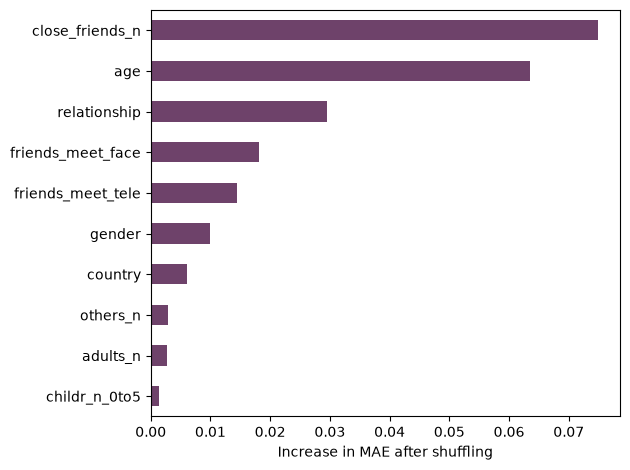

In [7]:
subset = test.sample(n=min(2000, len(test)), random_state=42)
importance = permutation_importance(
    saved["models"][selected], subset[saved["full"]], subset["ucla_total"],
    scoring="neg_mean_absolute_error", n_repeats=5, n_jobs=2, random_state=42,
)
importance_table = pd.DataFrame({"MAE increase": importance.importances_mean,
                                "SD across shuffles": importance.importances_std},
                                index=saved["full"]).sort_values("MAE increase", ascending=False)
importance_table.to_csv(tables / "permutation_importance.csv")
ax = importance_table.head(10)["MAE increase"].sort_values().plot.barh(color="#6e426a")
ax.set(xlabel="Increase in MAE after shuffling", ylabel="")
plt.tight_layout()
plt.savefig(figures / "05_predictive_importance.png", dpi=180)
plt.show()

## 7 Compare errors by age and municipality

Overall MAE can hide differences in how well the model predicts for different groups. We report groups with at least 30 test respondents because averages from very small groups can shift a lot with a few large errors.

In [8]:
groups = {
    "Age": pd.cut(test["age"], [15, 17, 29, 44, 59, np.inf],
                  labels=["16–17", "18–29", "30–44", "45–59", "60+"]),
    "Municipality": test["municipality_type_label"].where(test["municipality_type"].notna()),
}
group_errors = []
for variable, group in groups.items():
    summary = errors[[selected, "Median baseline"]].loc[:, lambda d: ~d.columns.duplicated()]
    summary = summary.groupby(group, observed=True).mean()
    summary["n"] = group.value_counts()
    group_errors.append(summary.loc[summary["n"] >= 30].assign(variable=variable))
subgroups = pd.concat(group_errors)
subgroups.to_csv(tables / "subgroup_test_errors.csv")
display(subgroups.round(3))

,Random forest,Median baseline,n,variable
16–17,1.449,1.594,32,Age
18–29,1.475,1.612,891,Age
30–44,1.434,1.531,1538,Age
45–59,1.447,1.594,1487,Age
60+,1.180,1.485,939,Age
A rural area or village,1.397,1.542,1180,Municipality
"Large town/ city (over 50,000 people)",1.419,1.570,2237,Municipality
"Small or medium-sized town (50,000 people or less)",1.363,1.545,1441,Municipality


## 8 Compare the two contact correlations

Both correlations come from the same respondents, so we resample their answers together. This gives us an interval for the difference between the correlations.

In [9]:
face = sample["friends_meet_face"].to_numpy()
remote = sample["friends_meet_tele"].to_numpy()
loneliness = sample["ucla_total"].to_numpy()
rho_difference = []
for _ in range(1000):
    draw = rng.integers(len(sample), size=len(sample))
    rho_difference.append(spearmanr(face[draw], loneliness[draw]).statistic
                          - spearmanr(remote[draw], loneliness[draw]).statistic)
comparison = pd.Series({
    "face_minus_remote": correlations["unweighted_rho"].iloc[0] - correlations["unweighted_rho"].iloc[1],
    "95% lower": np.quantile(rho_difference, .025),
    "95% upper": np.quantile(rho_difference, .975),
})
comparison.to_csv(tables / "paired_spearman_difference.csv")
display(comparison.round(3))

face_minus_remote   -0.034
95% lower           -0.045
95% upper           -0.023
dtype: float64

## 9 Summary

On the test set, the random forest had an average absolute error of 1.40 loneliness points, compared with 1.56 for the median baseline. Face-to-face contact had a slightly stronger negative association with loneliness than remote contact, both with and without survey weights. See the README for the findings and limitations.